<a href="https://colab.research.google.com/github/Lorenzito/ProgramacionParaAnaliticaDescriptivayPredicitva/blob/main/SVM_ClasesNoBalanceadas_273524.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Práctica 2: SVM con Tratamiento de Clases No Balanceadas
### Programación para Analítica Descriptiva y Predictiva · Semana 13 · Práctica 02
**Dataset:** `compustat.csv`

| | |
|---|---|
| **Nombre:** | Lorenzo Varela Ollervides |
| **Matrícula:** | 273524 |
| **Fecha:** | 10 de noviembre de 2026 |

**Objetivo:** aplicar técnicas de aprendizaje automático para el tratamiento de clases no balanceadas (SMOTEENN y One-Sided Selection) en un problema de clasificación real, usando un SVM con kernel RBF y comparando los resultados contra un modelo base sin balanceo.

---
## 1. Análisis Exploratorio de Datos (AED)

En esta sección se cargan las bibliotecas y el archivo `compustat.csv`, se separan las variables predictoras de la etiqueta de clase y se hace el análisis exploratorio que pide la práctica: el diagrama de barras con la distribución de las clases, los diagramas de densidad KDE de los atributos 5 y 13, y un análisis breve del nivel de desbalance.

In [1]:
# 1.1 Instalación de imbalanced-learn
# Esta librería trae los métodos de balanceo (SMOTEENN y One-Sided Selection) y el
# Pipeline que acepta remuestreo. Google Colab no la trae instalada por defecto.
!pip install imbalanced-learn -q

In [2]:
# 1.2 Bibliotecas
# Manejo de datos y gráficas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Modelo SVM y escalado de datos
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# Pipeline estándar de scikit-learn (para el modelo base, que no lleva remuestreo)
from sklearn.pipeline import Pipeline

# Pipeline de imbalanced-learn: es el que acepta un paso de remuestreo
from imblearn.pipeline import Pipeline as ImbPipeline

# Métodos de tratamiento del desbalance
from imblearn.combine import SMOTEENN
from imblearn.under_sampling import OneSidedSelection

# Validación cruzada estratificada y predicciones cruzadas
from sklearn.model_selection import StratifiedKFold, cross_val_predict

# Métricas de evaluación
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# Media geométrica (G-Mean), la métrica vista en la sesión para clases desbalanceadas
from imblearn.metrics import geometric_mean_score

# Semilla para que los resultados se puedan reproducir
SEMILLA = 42

# Colores que se usan en todas las gráficas: azul para la clase 0 y rojo para la clase 1
PALETA  = {'Clase 0': '#378ADD', 'Clase 1': '#E24B4A'}
COLORES = ['#378ADD', '#E24B4A']

# Para que las tablas muestren todas las columnas sin cortarlas
pd.set_option('display.max_columns', None)

In [3]:
# 1.3 Carga del conjunto de datos
# El archivo compustat.csv debe estar en la misma carpeta que el notebook
# (en Google Colab se sube al panel de archivos de la sesión)
df = pd.read_csv('compustat.csv')

# Tamaño del archivo y primeras filas para ver cómo vienen las columnas
print("Shape:", df.shape)
df.head()

Shape: (13657, 22)


,idx,at0,at1,at2,at3,at4,at5,at6,at7,at8,at9,at10,at11,at12,at13,at14,at15,at16,at17,at18,at19,label
0,0,0.076753,0.066548,0.132170,4.257882,0.771988,0.669344,0.076278,2.898450,6.081867,0.633688,0.036570,2.052378,0.372113,0.322636,0.250182,1.153351,0.451476,0.590680,0.512143,0.076278,0
1,1,0.097633,0.087736,0.162879,4.141787,0.781934,0.702665,0.082633,2.947445,6.272092,0.697423,0.043478,1.968984,0.371728,0.334043,0.231646,1.112813,0.409376,0.593143,0.533012,0.056273,0
2,2,0.025683,0.022020,0.152882,3.140505,0.698522,0.598883,0.097905,2.971928,6.508112,0.628921,0.053175,1.374306,0.305678,0.262075,0.220100,1.166375,0.487141,0.476098,0.408186,0.050251,0
3,3,0.011354,0.008987,0.165670,2.927575,0.699374,0.553558,0.107831,2.955952,6.588417,0.643100,0.057348,1.173407,0.280317,0.221873,0.245524,1.263416,0.487903,0.460482,0.364474,0.047244,0
4,4,0.001675,0.001212,0.155509,3.120983,0.689971,0.499122,0.098458,2.896668,6.607998,0.652961,0.047454,1.069792,0.236504,0.171086,0.271291,1.382369,0.464594,0.468896,0.339197,0.042986,0


In [4]:
# 1.4 Variables predictoras (X) y etiqueta de clase (y)
# y: la última columna (label) es la etiqueta de clase
y = df['label']

# X: se quitan idx (la primera columna, que es un índice y se ignora) y label (la etiqueta)
X = df.drop(columns=['idx', 'label'])

print("X (variables predictoras):", X.shape)
print("y (etiqueta de clase)    :", y.shape)
print("\nColumnas de X:")
print(list(X.columns))

X (variables predictoras): (13657, 20)
y (etiqueta de clase)    : (13657,)

Columnas de X:
['at0', 'at1', 'at2', 'at3', 'at4', 'at5', 'at6', 'at7', 'at8', 'at9', 'at10', 'at11', 'at12', 'at13', 'at14', 'at15', 'at16', 'at17', 'at18', 'at19']


### Diagrama de barras de la distribución de las clases

Lo primero es contar cuántas observaciones tiene cada clase. Se define una función que cuenta las observaciones por clase, dibuja el diagrama de barras (con el número de observaciones y el porcentaje sobre cada barra, y una línea punteada donde estaría el balance perfecto) e imprime el conteo.

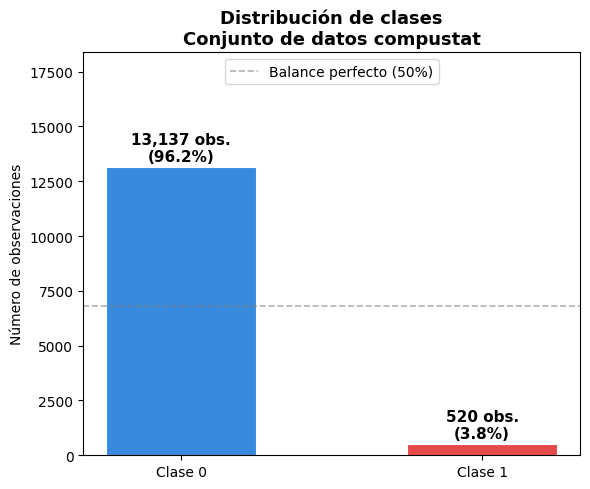

Total de observaciones : 13,657
Clase 0                : 13,137  (96.2%)
Clase 1                :    520  (3.8%)
Ratio mayoritaria / minoritaria : 25.3:1

Un clasificador trivial que prediga siempre la clase 0
obtendría 96.2% de accuracy sin aprender nada.


In [5]:
# 1.5 Función para mostrar la distribución de clases
def graficar_distribucion(y_datos, titulo):
    # Conteo de observaciones por clase, ordenado como clase 0 y clase 1
    conteo = y_datos.value_counts().sort_index()
    total  = conteo.sum()
    n_may  = conteo.max()   # clase con más observaciones
    n_min  = conteo.min()   # clase con menos observaciones

    fig, ax = plt.subplots(figsize=(6, 5))

    barras = ax.bar(
        ['Clase 0', 'Clase 1'],
        conteo,
        color     = COLORES,
        edgecolor = 'white',
        linewidth = 0.8,
        width     = 0.5
    )

    # Etiquetas sobre cada barra: valor absoluto y porcentaje
    for barra, val in zip(barras, conteo):
        ax.text(
            barra.get_x() + barra.get_width() / 2,
            barra.get_height() + n_may * 0.01,
            f'{val:,} obs.\n({val/total*100:.1f}%)',
            ha='center', va='bottom', fontsize=11, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.2', facecolor='white',
                      edgecolor='none', alpha=0.9)
        )

    # Línea de referencia: balance perfecto (la mitad del total en cada clase)
    ax.axhline(
        total / 2, color='gray', linestyle='--',
        linewidth=1.2, alpha=0.6, label='Balance perfecto (50%)'
    )

    ax.set_title(titulo, fontsize=13, fontweight='bold')
    ax.set_ylabel('Número de observaciones')
    ax.set_ylim(0, n_may * 1.40)
    ax.legend(fontsize=10, loc='upper center')

    plt.tight_layout()
    plt.show()

    # Conteo en texto
    print(f"Total de observaciones : {total:>6,}")
    print(f"Clase 0                : {conteo[0]:>6,}  ({conteo[0]/total*100:.1f}%)")
    print(f"Clase 1                : {conteo[1]:>6,}  ({conteo[1]/total*100:.1f}%)")
    print(f"Ratio mayoritaria / minoritaria : {n_may/n_min:.1f}:1")


# 1.6 Distribución de clases del conjunto de datos original
graficar_distribucion(y, 'Distribución de clases\nConjunto de datos compustat')

# Un clasificador que siempre predijera la clase mayoritaria acertaría en todas las
# observaciones de esa clase, es decir, en esta proporción del total:
print(f"\nUn clasificador trivial que prediga siempre la clase 0")
print(f"obtendría {(y == 0).sum()/len(y)*100:.1f}% de accuracy sin aprender nada.")

### Diagramas de densidad KDE para los atributos 5 y 13

Los atributos 5 y 13 son las columnas `at5` y `at13`. La curva de densidad (KDE) muestra la forma de la distribución de un atributo para cada clase; como cada curva se normaliza a la misma área, las dos clases se pueden comparar aunque tengan un número muy distinto de observaciones. La zona donde las dos curvas se enciman es la zona de solapamiento, donde ese atributo por sí solo no permite distinguir a qué clase pertenece una observación.

Cada atributo se grafica dos veces: en la fila de arriba con todos sus valores y en la fila de abajo solo con los valores que están entre sus percentiles 1 y 99, para poder ver la forma de las curvas en la zona donde está casi toda la información.

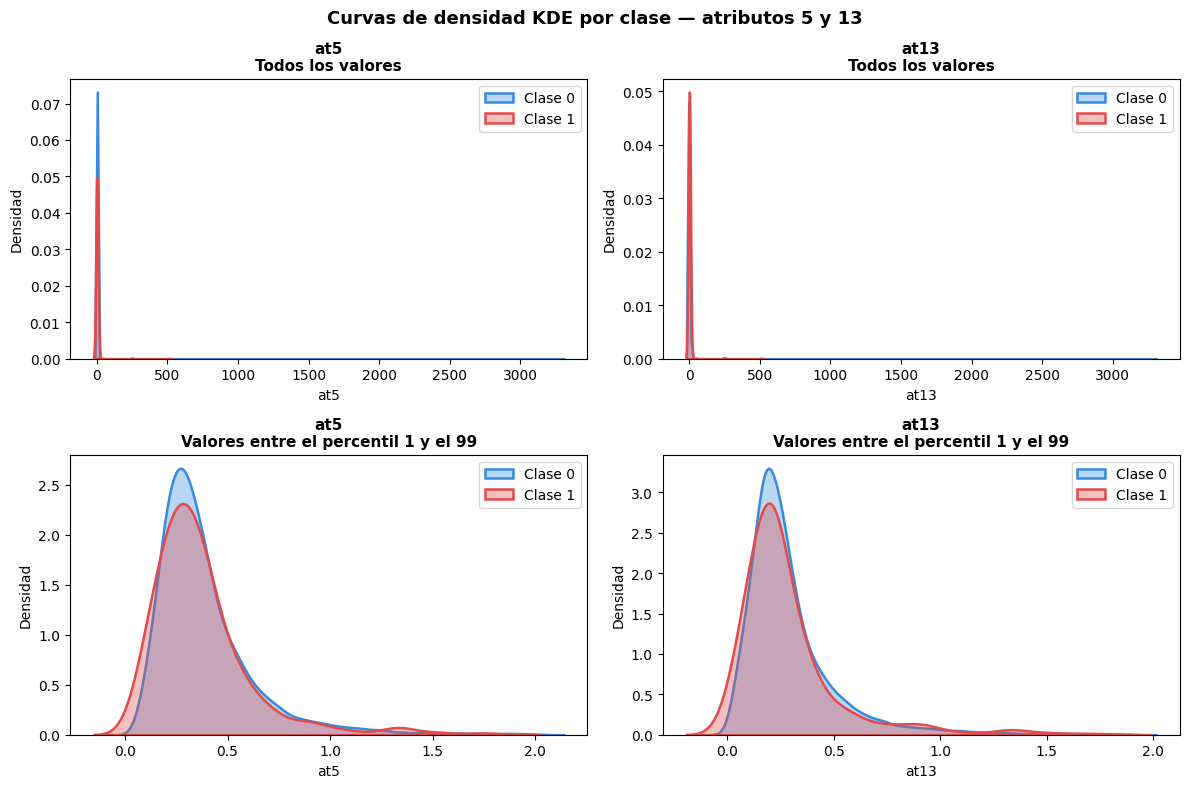

Resumen de los atributos graficados:
──────────────────────────────────────────────────────────────
at5
  Mínimo y máximo       : 0.00 a 3296.16
  Percentiles 1 y 99    : 0.06 a 2.04  (274 valores quedan fuera de este rango)
  Mediana clase 0       : 0.327
  Mediana clase 1       : 0.317
at13
  Mínimo y máximo       : -7.93 a 3296.16
  Percentiles 1 y 99    : 0.02 a 1.92  (274 valores quedan fuera de este rango)
  Mediana clase 0       : 0.237
  Mediana clase 1       : 0.223


In [6]:
# 1.7 Curvas de densidad KDE por clase para los atributos 5 y 13
# Columna de texto con el nombre de la clase, para la leyenda de las gráficas
df['etiqueta'] = df['label'].map({0: 'Clase 0', 1: 'Clase 1'})

atributos_kde = ['at5', 'at13']

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for j, atributo in enumerate(atributos_kde):

    # Fila de arriba: KDE con todos los valores del atributo
    ax = axes[0, j]
    for etiq, color in PALETA.items():
        sns.kdeplot(
            df.loc[df['etiqueta'] == etiq, atributo],
            ax        = ax,
            label     = etiq,
            color     = color,
            fill      = True,
            alpha     = 0.35,
            linewidth = 1.8
        )
    ax.set_title(f'{atributo}\nTodos los valores', fontsize=11, fontweight='bold')
    ax.set_xlabel(atributo)
    ax.set_ylabel('Densidad')
    ax.legend(fontsize=10)

    # Fila de abajo: KDE solo con los valores entre los percentiles 1 y 99
    # (se dejan fuera los valores extremos para ver la forma de las curvas)
    p01, p99 = df[atributo].quantile([0.01, 0.99])
    df_central = df[(df[atributo] >= p01) & (df[atributo] <= p99)]

    ax = axes[1, j]
    for etiq, color in PALETA.items():
        sns.kdeplot(
            df_central.loc[df_central['etiqueta'] == etiq, atributo],
            ax        = ax,
            label     = etiq,
            color     = color,
            fill      = True,
            alpha     = 0.35,
            linewidth = 1.8
        )
    ax.set_title(f'{atributo}\nValores entre el percentil 1 y el 99', fontsize=11, fontweight='bold')
    ax.set_xlabel(atributo)
    ax.set_ylabel('Densidad')
    ax.legend(fontsize=10)

plt.suptitle('Curvas de densidad KDE por clase — atributos 5 y 13',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Resumen numérico: rango completo de cada atributo, rango entre los percentiles 1 y 99
# y mediana de cada clase
print("Resumen de los atributos graficados:")
print("─" * 62)
for atributo in atributos_kde:
    p01, p99 = df[atributo].quantile([0.01, 0.99])
    fuera = ((df[atributo] < p01) | (df[atributo] > p99)).sum()
    med_0 = df.loc[df['label'] == 0, atributo].median()
    med_1 = df.loc[df['label'] == 1, atributo].median()
    print(f"{atributo}")
    print(f"  Mínimo y máximo       : {df[atributo].min():.2f} a {df[atributo].max():.2f}")
    print(f"  Percentiles 1 y 99    : {p01:.2f} a {p99:.2f}  ({fuera} valores quedan fuera de este rango)")
    print(f"  Mediana clase 0       : {med_0:.3f}")
    print(f"  Mediana clase 1       : {med_1:.3f}")

### Interpretación de los diagramas KDE

- **Con todos los valores (fila de arriba):** las dos curvas se ven como un solo pico pegado al cero y el resto del eje queda vacío. Esto pasa porque los dos atributos tienen unos cuantos valores extremos: `at5` va de 0.00 a 3296.16 y `at13` de -7.93 a 3296.16, pero entre los percentiles 1 y 99 `at5` solo va de 0.06 a 2.04 y `at13` de 0.02 a 1.92. En cada atributo quedan 274 valores fuera de ese rango, y son los que estiran el eje.
- **Entre los percentiles 1 y 99 (fila de abajo):** aquí ya se distingue la forma. En los dos atributos cada clase tiene un solo pico y una cola hacia la derecha, y las curvas de la clase 0 y de la clase 1 quedan casi una encima de la otra. Las medianas son casi iguales: 0.327 (clase 0) contra 0.317 (clase 1) en `at5`, y 0.237 contra 0.223 en `at13`. La curva de la clase 1 es un poco más baja en el pico y un poco más ancha, pero ocupa el mismo rango de valores que la de la clase 0.
- **Lectura:** el solapamiento entre clases es casi total en estos dos atributos. Ninguno de los dos, por sí solo, permite distinguir a qué clase pertenece una observación.

### Análisis del nivel de desbalance

El conjunto tiene 13,657 observaciones: 13,137 de la clase 0 (96.2%) y 520 de la clase 1 (3.8%). El ratio es de 25.3:1, es decir, por cada observación de la clase 1 hay unas 25 de la clase 0. En el diagrama de barras, la barra de la clase 1 apenas se levanta del eje y queda muy por debajo de la línea de balance perfecto.

Es un desbalance fuerte: la clase minoritaria no llega al 4% de los datos. Esto tiene dos consecuencias:

- El modelo tiene muy pocos ejemplos de la clase 1 para aprenderla, en comparación con los que tiene de la clase 0.
- Un clasificador que predijera siempre la clase 0 tendría 96.2% de accuracy sin haber aprendido nada, así que un accuracy alto en este conjunto no garantiza que el modelo detecte la clase 1.

Además, el desbalance se vuelve un problema real cuando se combina con solapamiento entre clases, y en los dos atributos graficados las clases están casi completamente solapadas.

---
## 2. Modelo Base

El modelo base (*baseline*) es un SVM con kernel RBF dentro de un `Pipeline` que primero escala los datos con `StandardScaler`. Se entrena con los datos tal como vienen, sin aplicar ningún método de tratamiento del desbalance, y sirve como referencia para comparar los modelos balanceados.

In [7]:
# 2.1 Pipeline del modelo base
# Paso 1: StandardScaler escala cada atributo (el SVM es sensible a la magnitud de las variables)
# Paso 2: SVM con kernel RBF, C=1.0 y gamma='scale'
pipeline_baseline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale'))
])

# 2.2 Entrenamiento del modelo base
# Se entrena con X e y originales: no hay ningún paso de balanceo en el pipeline
pipeline_baseline.fit(X, y)

print("Modelo base entrenado sin tratamiento de desbalance.")
print(f"Observaciones de entrenamiento : {len(y):,}")
print(f"  Clase 0 : {(y == 0).sum():,}")
print(f"  Clase 1 : {(y == 1).sum():,}")

Modelo base entrenado sin tratamiento de desbalance.
Observaciones de entrenamiento : 13,657
  Clase 0 : 13,137
  Clase 1 : 520


El modelo base quedó entrenado con las 13,657 observaciones en su proporción original (13,137 de la clase 0 y 520 de la clase 1), sin generar ni eliminar ninguna.

---
## 3. Tratamiento de Clases No Balanceadas

Se aplican dos métodos de tratamiento del desbalance y con cada uno se vuelve a entrenar el SVM:

- **SMOTEENN:** combina sobremuestreo y limpieza. Primero SMOTE genera observaciones sintéticas de la clase minoritaria interpolando entre observaciones reales y sus vecinos más cercanos; después ENN (*Edited Nearest Neighbors*) elimina las observaciones cuya clase no coincide con la de la mayoría de sus vecinos cercanos.
- **One-Sided Selection (OSS):** es un método de submuestreo. Elimina ejemplos ambiguos de la clase mayoritaria; no genera observaciones sintéticas.

Para cada método se hacen dos cosas:

1. **Mostrar la nueva distribución de clases.** El método se aplica a las 13,657 observaciones (ya escaladas, porque estos métodos trabajan con los vecinos más cercanos de cada observación, es decir, con distancias) y se cuentan las observaciones que quedan de cada clase. Este remuestreo de todo el conjunto solo sirve para ver cómo cambia la distribución: los datos que resultan de él no se usan para entrenar ni para evaluar ningún modelo.
2. **Entrenar de nuevo el SVM con los datos balanceados.** El balanceo va como un paso dentro del pipeline (escalado, balanceo y SVM), de modo que solo se aplica a los datos con los que el pipeline se entrena. Para eso se usa el `Pipeline` de imbalanced-learn (`ImbPipeline`), que acepta un paso de remuestreo, cosa que el `Pipeline` estándar de scikit-learn no permite.

### SMOTEENN

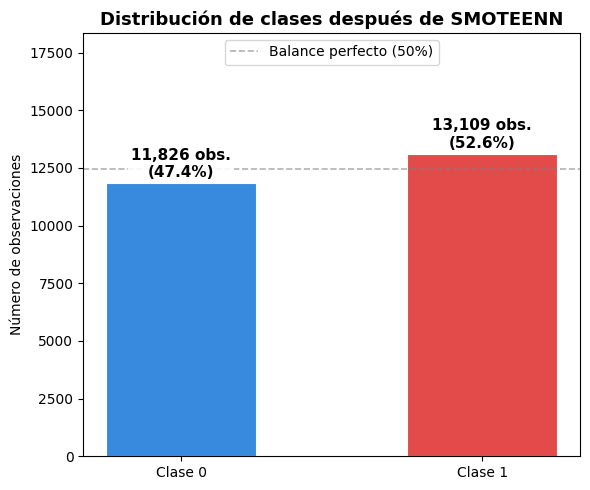

Total de observaciones : 24,935
Clase 0                : 11,826  (47.4%)
Clase 1                : 13,109  (52.6%)
Ratio mayoritaria / minoritaria : 1.1:1

Clase 0: de 13,137 a 11,826 observaciones
Clase 1: de 520 a 13,109 observaciones


In [8]:
# 3.1 Nueva distribución de clases con SMOTEENN
# Se escalan los datos (igual que hace el pipeline) y se aplica SMOTEENN.
# Esto es solo para mostrar la distribución: X_smoteenn e y_smoteenn no se usan para entrenar.
X_escalado = StandardScaler().fit_transform(X)

smoteenn = SMOTEENN(random_state=SEMILLA)
X_smoteenn, y_smoteenn = smoteenn.fit_resample(X_escalado, y)

graficar_distribucion(y_smoteenn, 'Distribución de clases después de SMOTEENN')

# Cambio respecto a los datos originales
print(f"\nClase 0: de {(y == 0).sum():,} a {(y_smoteenn == 0).sum():,} observaciones")
print(f"Clase 1: de {(y == 1).sum():,} a {(y_smoteenn == 1).sum():,} observaciones")

**Nueva distribución con SMOTEENN:** el conjunto pasa de 13,657 a 24,935 observaciones. La clase 1 crece de 520 a 13,109 (las que se agregan son observaciones sintéticas generadas por SMOTE) y la clase 0 baja de 13,137 a 11,826, es decir, la limpieza con ENN le quita 1,311 observaciones. Las clases quedan en 47.4% y 52.6%, con un ratio de 1.1:1: prácticamente balanceadas, e incluso con la clase 1 un poco por arriba de la clase 0.

In [9]:
# 3.2 SVM entrenado con los datos balanceados con SMOTEENN
# El pipeline hace los tres pasos en orden: escala, balancea con SMOTEENN y entrena el SVM
pipeline_smoteenn = ImbPipeline([
    ('scaler', StandardScaler()),
    ('smoteenn', SMOTEENN(random_state=SEMILLA)),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale'))
])

pipeline_smoteenn.fit(X, y)

print("SVM entrenado con los datos balanceados con SMOTEENN.")

SVM entrenado con los datos balanceados con SMOTEENN.


### One-Sided Selection

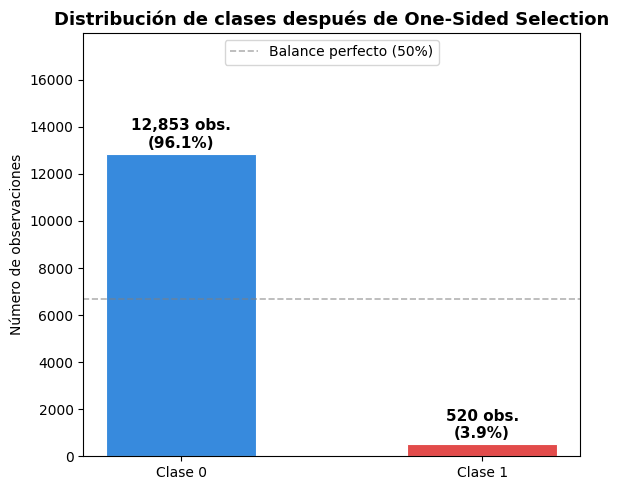

Total de observaciones : 13,373
Clase 0                : 12,853  (96.1%)
Clase 1                :    520  (3.9%)
Ratio mayoritaria / minoritaria : 24.7:1

Clase 0: de 13,137 a 12,853 observaciones
Clase 1: de 520 a 520 observaciones


In [10]:
# 3.3 Nueva distribución de clases con One-Sided Selection
# Se aplica sobre los mismos datos escalados de la celda 3.1.
# Esto es solo para mostrar la distribución: X_oss e y_oss no se usan para entrenar.
oss = OneSidedSelection(random_state=SEMILLA)
X_oss, y_oss = oss.fit_resample(X_escalado, y)

graficar_distribucion(y_oss, 'Distribución de clases después de One-Sided Selection')

# Cambio respecto a los datos originales
print(f"\nClase 0: de {(y == 0).sum():,} a {(y_oss == 0).sum():,} observaciones")
print(f"Clase 1: de {(y == 1).sum():,} a {(y_oss == 1).sum():,} observaciones")

**Nueva distribución con One-Sided Selection:** el cambio es mucho menor. Solo se eliminan 284 observaciones de la clase 0 (de 13,137 a 12,853) y la clase 1 conserva sus 520. El conjunto baja de 13,657 a 13,373 observaciones y la proporción casi no se mueve: 96.1% contra 3.9%, con un ratio de 24.7:1 (antes 25.3:1). One-Sided Selection limpia la clase mayoritaria, pero no deja las clases equilibradas.

In [11]:
# 3.4 SVM entrenado con los datos balanceados con One-Sided Selection
# El pipeline hace los tres pasos en orden: escala, aplica One-Sided Selection y entrena el SVM
pipeline_oss = ImbPipeline([
    ('scaler', StandardScaler()),
    ('oss', OneSidedSelection(random_state=SEMILLA)),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale'))
])

pipeline_oss.fit(X, y)

print("SVM entrenado con los datos balanceados con One-Sided Selection.")

SVM entrenado con los datos balanceados con One-Sided Selection.


---
## 4. Entrenamiento y Evaluación del Modelo

Los tres modelos (base, SMOTEENN y One-Sided Selection) se entrenan y evalúan con validación cruzada estratificada de 5 particiones. `StratifiedKFold` conserva la proporción de clases en cada partición, lo que importa en un conjunto desbalanceado porque así ninguna partición se queda con muy pocos ejemplos de la clase minoritaria.

Los tres modelos son pipelines (secciones 2 y 3), y eso es lo que evita el *data leakage*. En cada una de las 5 particiones el pipeline se vuelve a ajustar solo con la parte de entrenamiento:

| Momento | Lo que ejecuta el pipeline |
|---|---|
| Entrenamiento de la partición | `StandardScaler` aprende la media y la desviación estándar solo de la parte de entrenamiento → el método de balanceo se aplica solo a la parte de entrenamiento → se entrena el SVM con kernel RBF |
| Validación de la partición | se escala con la media y la desviación aprendidas en entrenamiento → el SVM predice (sin balanceo) |

Así, la parte de validación no influye ni en el escalado ni en el balanceo, y las predicciones se hacen siempre sobre observaciones reales con la distribución de clases original.

In [12]:
# 4.1 Validación cruzada estratificada de 5 particiones
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEMILLA
)

# Composición de cada partición: cuántas observaciones y cuántas de la clase 1
# quedan en la parte de entrenamiento y en la de validación
print("=== Distribución de clases por partición ===\n")

for fold, (idx_tr, idx_val) in enumerate(cv.split(X, y), 1):

    n_min_tr  = (y.iloc[idx_tr] == 1).sum()
    n_min_val = (y.iloc[idx_val] == 1).sum()

    print(
        f"Partición {fold}: "
        f"entrenamiento={len(idx_tr):,} (clase 1={n_min_tr}) | "
        f"validación={len(idx_val):,} (clase 1={n_min_val})"
    )

=== Distribución de clases por partición ===

Partición 1: entrenamiento=10,925 (clase 1=416) | validación=2,732 (clase 1=104)
Partición 2: entrenamiento=10,925 (clase 1=416) | validación=2,732 (clase 1=104)
Partición 3: entrenamiento=10,926 (clase 1=416) | validación=2,731 (clase 1=104)
Partición 4: entrenamiento=10,926 (clase 1=416) | validación=2,731 (clase 1=104)
Partición 5: entrenamiento=10,926 (clase 1=416) | validación=2,731 (clase 1=104)


In [13]:
# 4.2 Entrenamiento y evaluación de los tres modelos con la validación cruzada
# cross_val_predict entrena el pipeline en cada partición y predice su parte de validación;
# al final cada observación tiene una predicción hecha por un modelo que no la vio al entrenar

# Modelo base (sin balanceo)
y_pred_baseline = cross_val_predict(pipeline_baseline, X, y, cv=cv)

# SVM con SMOTEENN
y_pred_smoteenn = cross_val_predict(pipeline_smoteenn, X, y, cv=cv)

# SVM con One-Sided Selection
y_pred_oss = cross_val_predict(pipeline_oss, X, y, cv=cv)

# Predicciones de cada modelo, para usarlas en la evaluación
predicciones = {
    'Baseline (sin balanceo)': y_pred_baseline,
    'SMOTEENN': y_pred_smoteenn,
    'One-Sided Selection': y_pred_oss
}

print("Predicciones obtenidas con la validación cruzada:")
for nombre, y_pred in predicciones.items():
    print(f"  {nombre:<24}: {len(y_pred):,} predicciones")

Predicciones obtenidas con la validación cruzada:
  Baseline (sin balanceo) : 13,657 predicciones
  SMOTEENN                : 13,657 predicciones
  One-Sided Selection     : 13,657 predicciones


Las 5 particiones quedaron con 10,925 o 10,926 observaciones de entrenamiento y 2,732 o 2,731 de validación, y todas con la misma cantidad de observaciones de la clase 1: 416 en entrenamiento y 104 en validación. En cada partición, el escalado y el balanceo se ajustan solo con esas observaciones de entrenamiento, y las de validación solo se usan para predecir. Cada modelo tiene 13,657 predicciones, una por cada observación del conjunto.

---
## 5. Evaluación de Resultados

Con las predicciones de la validación cruzada (sección 4) se calculan Accuracy, Precision, Recall, F1-score y G-Mean de cada modelo, y su matriz de confusión.

- Precision, Recall y F1-score se calculan para la clase 1, que es la clase minoritaria.
- G-Mean es la media geométrica del recall de las dos clases, $\sqrt{TPR \times TNR}$, donde TPR es el recall de la clase 1 y TNR el de la clase 0. Es la métrica vista en la sesión para clases desbalanceadas, porque vale 0 cuando el modelo ignora por completo alguna de las clases.

Las métricas se reportan de dos formas: con las predicciones de las 5 particiones juntas, y por separado en cada partición, con su media y su desviación estándar.

### Accuracy, Precision, Recall, F1-score y G-Mean

In [14]:
# 5.1 Métricas de cada modelo
# Se calculan con las predicciones de las 5 particiones juntas (una por observación)
metricas = ['Accuracy', 'Precision', 'Recall', 'F1-score', 'G-Mean']

resultados = []

for nombre, y_pred in predicciones.items():
    resultados.append([
        nombre,
        accuracy_score(y, y_pred),                      # proporción de aciertos sobre el total
        precision_score(y, y_pred, zero_division=0),    # de lo predicho como clase 1, cuánto sí lo era
        recall_score(y, y_pred),                        # de la clase 1 real, cuánta se detectó
        f1_score(y, y_pred, zero_division=0),           # media armónica de precision y recall
        geometric_mean_score(y, y_pred)                 # raíz de (recall de la clase 1 x recall de la clase 0)
    ])

tabla = pd.DataFrame(
    resultados,
    columns=['Modelo'] + metricas
)

print("=== Métricas con validación cruzada estratificada de 5 particiones ===")
print("(Precision, Recall y F1-score corresponden a la clase 1)\n")

# Se muestra con 4 decimales
display(tabla.round(4))

=== Métricas con validación cruzada estratificada de 5 particiones ===
(Precision, Recall y F1-score corresponden a la clase 1)



,Modelo,Accuracy,Precision,Recall,F1-score,G-Mean
0,Baseline (sin balanceo),0.9622,1.0000,0.0077,0.0153,0.0877
1,SMOTEENN,0.8112,0.1439,0.8000,0.2439,0.8058
2,One-Sided Selection,0.9622,0.7500,0.0115,0.0227,0.1074


In [15]:
# 5.2 Métricas por partición
# Las mismas métricas, calculadas por separado en cada una de las 5 particiones.
# cv.split(X, y) regresa las mismas particiones que se usaron en la sección 4 (misma semilla),
# así que solo se toman las predicciones que ya se tienen de cada parte de validación.
resultados_fold = []

for nombre, y_pred in predicciones.items():

    for fold, (idx_tr, idx_val) in enumerate(cv.split(X, y), 1):

        y_val    = y.iloc[idx_val]   # clases reales de la parte de validación
        pred_val = y_pred[idx_val]   # predicciones de esa misma parte

        resultados_fold.append({
            'Modelo'    : nombre,
            'Partición' : fold,
            'Accuracy'  : accuracy_score(y_val, pred_val),
            'Precision' : precision_score(y_val, pred_val, zero_division=0),
            'Recall'    : recall_score(y_val, pred_val),
            'F1-score'  : f1_score(y_val, pred_val, zero_division=0),
            'G-Mean'    : geometric_mean_score(y_val, pred_val)
        })

tabla_fold = pd.DataFrame(resultados_fold)

print("=== Métricas por partición ===\n")

display(tabla_fold.round(4))

# Media y desviación estándar de las 5 particiones, para cada modelo y cada métrica
resumen_fold = []

for nombre in predicciones:

    filas = tabla_fold[tabla_fold['Modelo'] == nombre]

    fila_resumen = {'Modelo': nombre}
    for metrica in metricas:
        fila_resumen[metrica] = f"{np.mean(filas[metrica]):.4f} ± {np.std(filas[metrica]):.4f}"

    resumen_fold.append(fila_resumen)

print("\n=== Media ± desviación estándar de las 5 particiones ===\n")

display(pd.DataFrame(resumen_fold))

=== Métricas por partición ===



,Modelo,Partición,Accuracy,Precision,Recall,F1-score,G-Mean
0,Baseline (sin balanceo),1,0.9619,0.0000,0.0000,0.0000,0.0000
1,Baseline (sin balanceo),2,0.9619,0.0000,0.0000,0.0000,0.0000
2,Baseline (sin balanceo),3,0.9623,1.0000,0.0096,0.0190,0.0981
3,Baseline (sin balanceo),4,0.9627,1.0000,0.0192,0.0377,0.1387
4,Baseline (sin balanceo),5,0.9623,1.0000,0.0096,0.0190,0.0981
5,SMOTEENN,1,0.8166,0.1524,0.8365,0.2578,0.8261
6,SMOTEENN,2,0.8049,0.1308,0.7308,0.2219,0.7683
7,SMOTEENN,3,0.8078,0.1352,0.7500,0.2291,0.7794
8,SMOTEENN,4,0.8155,0.1503,0.8269,0.2544,0.8209
9,SMOTEENN,5,0.8111,0.1508,0.8558,0.2565,0.8322



=== Media ± desviación estándar de las 5 particiones ===



,Modelo,Accuracy,Precision,Recall,F1-score,G-Mean
0,Baseline (sin balanceo),0.9622 ± 0.0003,0.6000 ± 0.4899,0.0077 ± 0.0072,0.0152 ± 0.0141,0.0670 ± 0.0566
1,SMOTEENN,0.8112 ± 0.0044,0.1439 ± 0.0090,0.8000 ± 0.0499,0.2439 ± 0.0153,0.8054 ± 0.0262
2,One-Sided Selection,0.9622 ± 0.0001,0.8333 ± 0.2108,0.0115 ± 0.0038,0.0227 ± 0.0074,0.1062 ± 0.0162


In [16]:
# 5.3 Reporte de clasificación de cada modelo
# Muestra precision, recall y F1-score de las dos clases, no solo de la clase 1
for nombre, y_pred in predicciones.items():
    print("=" * 60)
    print(nombre)
    print("=" * 60)
    print(
        classification_report(
            y,
            y_pred,
            target_names=['Clase 0', 'Clase 1'],
            zero_division=0
        )
    )

Baseline (sin balanceo)
              precision    recall  f1-score   support

     Clase 0       0.96      1.00      0.98     13137
     Clase 1       1.00      0.01      0.02       520

    accuracy                           0.96     13657
   macro avg       0.98      0.50      0.50     13657
weighted avg       0.96      0.96      0.94     13657

SMOTEENN
              precision    recall  f1-score   support

     Clase 0       0.99      0.81      0.89     13137
     Clase 1       0.14      0.80      0.24       520

    accuracy                           0.81     13657
   macro avg       0.57      0.81      0.57     13657
weighted avg       0.96      0.81      0.87     13657

One-Sided Selection
              precision    recall  f1-score   support

     Clase 0       0.96      1.00      0.98     13137
     Clase 1       0.75      0.01      0.02       520

    accuracy                           0.96     13657
   macro avg       0.86      0.51      0.50     13657
weighted avg       0.

### Matriz de confusión

Baseline (sin balanceo)
  TN = 13,137   FP =      0
  FN =    516   TP =      4

SMOTEENN
  TN = 10,662   FP =  2,475
  FN =    104   TP =    416

One-Sided Selection
  TN = 13,135   FP =      2
  FN =    514   TP =      6



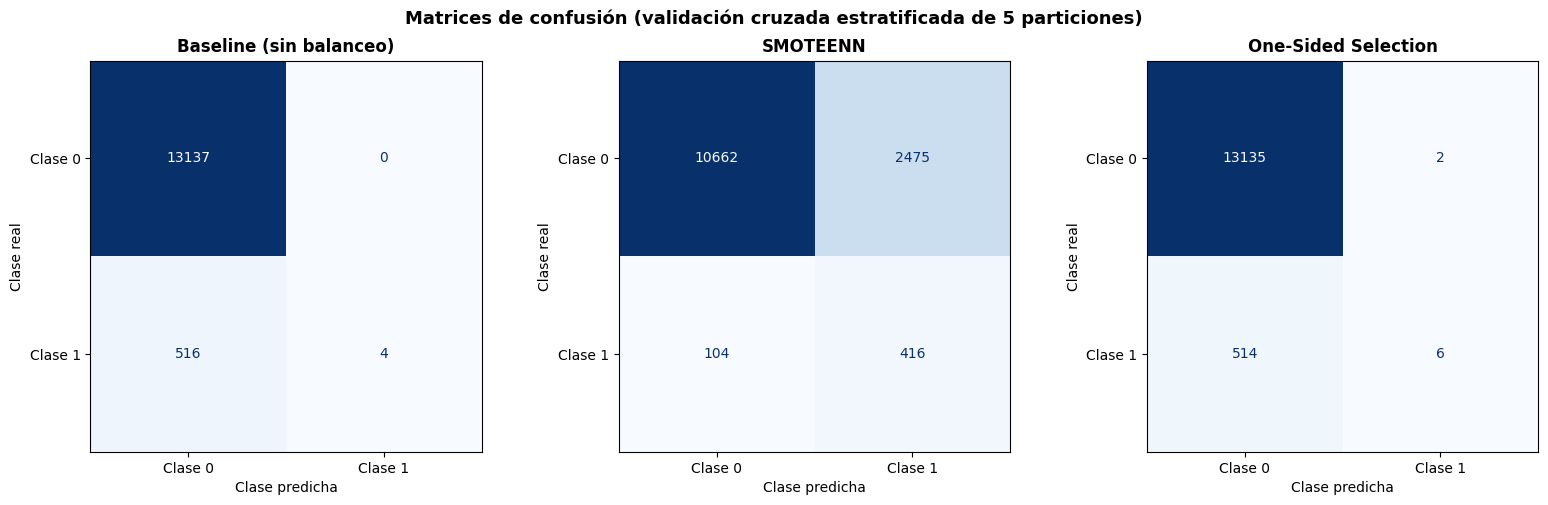

In [17]:
# 5.4 Matriz de confusión de cada modelo
# Filas: clase real. Columnas: clase predicha.
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (nombre, y_pred) in zip(axes, predicciones.items()):

    cm = confusion_matrix(y, y_pred)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['Clase 0', 'Clase 1']
    )
    disp.plot(ax=ax, colorbar=False, cmap='Blues')

    ax.set_title(nombre, fontsize=12, fontweight='bold')
    ax.set_xlabel('Clase predicha')
    ax.set_ylabel('Clase real')
    ax.grid(False)

    # La misma matriz en texto, con el nombre de cada casilla
    TN = cm[0, 0]   # clase 0 predicha correctamente
    FP = cm[0, 1]   # clase 0 predicha como clase 1
    FN = cm[1, 0]   # clase 1 predicha como clase 0
    TP = cm[1, 1]   # clase 1 predicha correctamente

    print(f"{nombre}")
    print(f"  TN = {TN:>6,}   FP = {FP:>6,}")
    print(f"  FN = {FN:>6,}   TP = {TP:>6,}\n")

plt.suptitle('Matrices de confusión (validación cruzada estratificada de 5 particiones)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### Gráfica comparativa de métricas

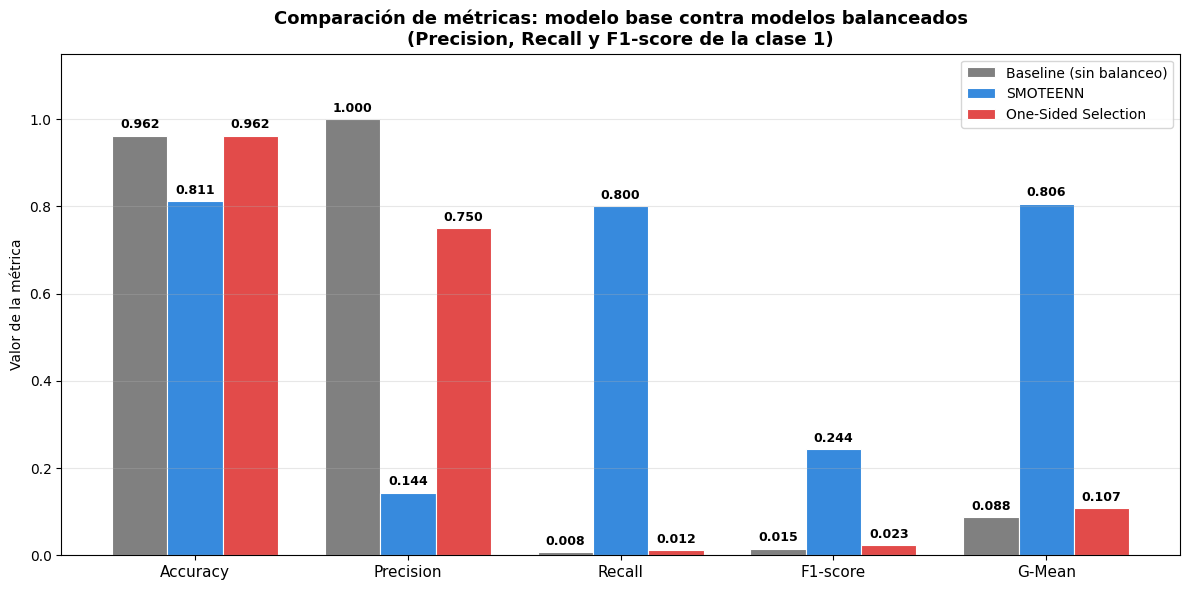

In [18]:
# 5.5 Gráfica comparativa: una barra por modelo en cada métrica
# Se grafican las métricas de la tabla 5.1 (lista 'metricas')

# Gris para el modelo de referencia y un color para cada método de balanceo
colores_modelos = ['gray', '#378ADD', '#E24B4A']

posiciones = np.arange(len(metricas))   # posición de cada métrica en el eje x
ancho      = 0.26                       # ancho de cada barra

fig, ax = plt.subplots(figsize=(12, 6))

for i, fila in tabla.iterrows():

    # Las barras de cada modelo se recorren para que queden una junto a otra
    barras = ax.bar(
        posiciones + (i - 1) * ancho,
        fila[metricas],
        width     = ancho,
        color     = colores_modelos[i],
        edgecolor = 'white',
        linewidth = 0.8,
        label     = fila['Modelo']
    )

    # Valor de la métrica sobre cada barra
    for barra, val in zip(barras, fila[metricas]):
        ax.text(
            barra.get_x() + barra.get_width() / 2,
            barra.get_height() + 0.01,
            f'{val:.3f}',
            ha='center', va='bottom', fontsize=9, fontweight='bold'
        )

ax.set_xticks(posiciones)
ax.set_xticklabels(metricas, fontsize=11)
ax.set_ylabel('Valor de la métrica')
ax.set_ylim(0, 1.15)
ax.set_title('Comparación de métricas: modelo base contra modelos balanceados\n'
             '(Precision, Recall y F1-score de la clase 1)',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=10, loc='upper right')
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

### Comparación del modelo base contra los modelos balanceados

- **Modelo base (sin balanceo):** tiene un accuracy de 0.9622, pero un recall de 0.0077: de las 520 observaciones de la clase 1 solo detecta 4 (TP = 4) y deja pasar 516 (FN = 516). No se equivoca nunca con la clase 0 (TN = 13,137 y FP = 0), y por eso su precision es de 1.0000, pero ese valor sale de solo 4 predicciones de clase 1. De sus 13,657 predicciones, 13,653 son clase 0. Su F1-score es de 0.0153 y su G-Mean de 0.0877.
- **SMOTEENN:** el recall sube de 0.0077 a 0.8000: detecta 416 de las 520 observaciones de la clase 1 y deja pasar 104. El costo está en la clase 0: 2,475 observaciones de la clase 0 se predicen como clase 1 (FP), con lo que la precision baja a 0.1439 (de cada 100 observaciones que el modelo marca como clase 1, unas 14 lo son) y el recall de la clase 0 baja de 1.00 a 0.81. El accuracy baja a 0.8112, pero el F1-score sube de 0.0153 a 0.2439 y el G-Mean de 0.0877 a 0.8058.
- **One-Sided Selection:** queda prácticamente igual que el modelo base. Detecta 6 de las 520 observaciones de la clase 1 (2 más que el modelo base), con un recall de 0.0115, y tiene 2 falsos positivos, por lo que su precision es de 0.7500 (6 de 8 predicciones de clase 1). Su F1-score es de 0.0227, su G-Mean de 0.1074 y su accuracy es el mismo que el del modelo base, 0.9622: los dos aciertan en 13,141 observaciones (13,137 + 4 el modelo base y 13,135 + 6 One-Sided Selection).

En la gráfica comparativa se ve el mismo patrón: en Accuracy y Precision las barras del modelo base y de One-Sided Selection son las más altas, y en Recall, F1-score y G-Mean la única barra que se levanta es la de SMOTEENN.

**Resultados por partición.** La diferencia entre los modelos se repite en las 5 particiones, no depende de una sola:

- SMOTEENN tiene un recall de entre 0.7308 y 0.8558 (0.8000 ± 0.0499) y un G-Mean de entre 0.7683 y 0.8322 (0.8054 ± 0.0262). Su F1-score es de 0.2439 ± 0.0153.
- El modelo base no detecta ninguna observación de la clase 1 en las particiones 1 y 2 (recall y G-Mean de 0.0000), y en las otras tres detecta 1 o 2 de las 104 que hay en validación (recall de 0.0096 y 0.0192). Su G-Mean es de 0.0670 ± 0.0566.
- One-Sided Selection detecta 1 o 2 de las 104 en cada partición (recall de 0.0115 ± 0.0038), con un G-Mean de 0.1062 ± 0.0162.
- El valor más bajo de SMOTEENN en una partición (recall de 0.7308 y G-Mean de 0.7683) queda muy por arriba del más alto de los otros dos modelos (recall de 0.0192 y G-Mean de 0.1387).
- El accuracy casi no cambia de una partición a otra: 0.9622 ± 0.0003 en el modelo base, 0.9622 ± 0.0001 en One-Sided Selection y 0.8112 ± 0.0044 en SMOTEENN.

En la precision del modelo base la media por partición (0.6000 ± 0.4899) no coincide con el 1.0000 de las predicciones juntas. La razón es que en las particiones 1 y 2 el modelo no predice ninguna observación como clase 1 y ahí la precision se toma como 0 (`zero_division=0`), mientras que en las otras tres es de 1.0000. Con tan pocas predicciones de clase 1 (4 del modelo base y 8 de One-Sided Selection), la precision de estos dos modelos es muy inestable: en One-Sided Selection va de 0.5000 a 1.0000 según la partición.

### ¿Es suficiente Accuracy para evaluar el problema?

No. En este conjunto el accuracy por sí solo lleva a la conclusión equivocada:

- El modelo base tiene 0.9622 de accuracy, que parece excelente, pero es casi lo mismo que obtendría un clasificador que predijera siempre la clase 0 (96.2%, sección 1). La matriz de confusión muestra lo que ese número esconde: el modelo encuentra 4 de las 520 observaciones de la clase 1. Es la paradoja de la accuracy: como el 96.2% de las observaciones son de la clase 0, los aciertos en esa clase dominan el cálculo y casi no importa lo que pase con la clase 1. El G-Mean lo deja ver en un solo número: el mismo modelo tiene 0.9622 de accuracy y 0.0877 de G-Mean.
- El accuracy ordena los modelos al revés de su capacidad para detectar la clase minoritaria. SMOTEENN tiene el accuracy más bajo (0.8112) y es el único que detecta la clase 1 (recall de 0.8000 y G-Mean de 0.8058). El modelo base y One-Sided Selection empatan con el accuracy más alto (0.9622) y dejan pasar 516 y 514 de las 520 observaciones de la clase 1.

Por eso hacen falta las otras métricas: el recall dice qué parte de la clase 1 se detecta, la precision dice qué tan confiables son las predicciones de clase 1, el F1-score resume las dos, el G-Mean dice si el modelo reconoce las dos clases y la matriz de confusión muestra de qué tipo son los errores (falsos negativos o falsos positivos).

---
## 6. Discusión y Conclusiones

### El impacto del desbalance sobre el desempeño del modelo

Con 96.2% de las observaciones en la clase 0 y 3.8% en la clase 1 (ratio de 25.3:1), el SVM sin balanceo aprende a predecir casi siempre la clase mayoritaria: 13,653 de sus 13,657 predicciones son clase 0. Acierta en toda la clase 0, pero su recall en la clase 1 es de 0.0077 (4 de 520), su F1-score de 0.0153 y su G-Mean de 0.0877. En los términos vistos en la sesión, la frontera de decisión queda desplazada hacia la clase mayoritaria: la región que el modelo le asigna a la clase 1 casi desaparece (solo 4 predicciones de clase 1).

Una explicación posible de que el efecto sea tan fuerte es que el desbalance venga acompañado de solapamiento, que es cuando el desbalance se vuelve un problema real. En los dos atributos graficados en la sección 1 (`at5` y `at13`) las curvas de las dos clases quedan casi una encima de la otra; con tan pocos ejemplos de la clase 1 (416 en cada partición de entrenamiento) en una zona que comparte con la clase 0, al modelo le resultaría mejor asignar esa zona a la clase mayoritaria. Esto no queda demostrado con lo que se hizo aquí: solo se graficaron 2 de los 20 atributos, y dos clases pueden estar solapadas en cada atributo por separado y distinguirse al combinar varios.

El desbalance también afecta la forma de medir: el accuracy de 0.9622 no refleja nada de esto, porque es prácticamente el que se obtiene prediciendo siempre la clase 0 (96.2%).

### Las diferencias observadas entre SMOTEENN y One-Sided Selection

| | SMOTEENN | One-Sided Selection |
|---|---|---|
| Qué hace con los datos | Genera observaciones sintéticas de la clase 1 y después limpia | Solo elimina observaciones de la clase 0 |
| Clase 0 después del balanceo | 11,826 (antes 13,137) | 12,853 (antes 13,137) |
| Clase 1 después del balanceo | 13,109 (antes 520) | 520 (sin cambio) |
| Ratio después del balanceo | 1.1:1 | 24.7:1 |
| Accuracy | 0.8112 | 0.9622 |
| Precision (clase 1) | 0.1439 | 0.7500 |
| Recall (clase 1) | 0.8000 | 0.0115 |
| F1-score (clase 1) | 0.2439 | 0.0227 |
| G-Mean | 0.8058 | 0.1074 |
| Falsos negativos / falsos positivos | 104 / 2,475 | 514 / 2 |

- **En los datos:** SMOTEENN cambia por completo la distribución (de 25.3:1 a 1.1:1), mientras que One-Sided Selection solo quita 284 observaciones de la clase 0 y deja el conjunto casi tan desbalanceado como estaba (24.7:1).
- **En el modelo:** con SMOTEENN el SVM cambia de comportamiento y empieza a predecir la clase 1: detecta 416 de 520. Con One-Sided Selection el SVM se comporta casi igual que el modelo base: detecta 6 de 520, contra 4 del modelo base.
- **En el tipo de error:** SMOTEENN gana sensibilidad a cambio de falsos positivos (2,475, con lo que el recall de la clase 0 baja a 0.81). One-Sided Selection conserva casi intacta la clase mayoritaria (13,135 de 13,137 bien clasificadas), pero no recupera la minoritaria. Coincide con lo visto en la sesión: el sobremuestreo con SMOTE sube la detección de la clase minoritaria y puede generar más falsos positivos cuando hay solapamiento, y One-Sided Selection preserva mejor la clase mayoritaria.

La diferencia se explica por lo que cada método le deja al modelo: One-Sided Selection no le da más ejemplos de la clase 1, y después de la limpieza el SVM sigue viendo unas 25 observaciones de la clase 0 por cada una de la clase 1.

### Qué método produjo los mejores resultados y por qué

**SMOTEENN.** Es el único de los tres modelos que detecta la clase minoritaria: tiene el recall más alto (0.8000, contra 0.0115 de One-Sided Selection y 0.0077 del modelo base), el F1-score más alto (0.2439, contra 0.0227 y 0.0153) y el G-Mean más alto (0.8058, contra 0.1074 y 0.0877). En la matriz de confusión eso significa 416 observaciones de la clase 1 detectadas, contra 6 y 4. La ventaja se mantiene en las 5 particiones: su recall más bajo en una partición es de 0.7308, y el más alto de los otros dos modelos es de 0.0192.

La explicación más directa es que es el único método que realmente dejó balanceados los datos (ratio de 1.1:1 al aplicarlo al conjunto completo, sección 3): el SVM ve casi tantos ejemplos de la clase 1 como de la clase 0, así que ya no le conviene asignar casi todo a la clase mayoritaria. Además, ENN elimina las observaciones cuya clase no coincide con la de la mayoría de sus vecinos, que son las de las zonas ambiguas.

Ese resultado tiene un costo: la precision de SMOTEENN es de 0.1439, lo que equivale a 2,475 falsos positivos, casi 6 por cada observación de la clase 1 que detecta, y su accuracy baja a 0.8112. Si se juzgara solo por accuracy, ganarían el modelo base y One-Sided Selection (0.9622), pero esos dos modelos equivalen casi a predecir siempre la clase 0. Cuando lo que importa es detectar la clase minoritaria, como en los ejemplos de fraude o de diagnóstico vistos en la sesión, donde un falso negativo cuesta más que un falso positivo, SMOTEENN es el mejor de los tres.

Aun así, su F1-score de 0.2439 sigue siendo bajo, por la precision de 0.1439: con el balanceo el modelo ya detecta la clase 1, pero la sigue confundiendo con una parte de la clase 0 (2,475 falsos positivos).